### Загрузка датасета

In [3]:
import os
import pandas as pd
import kagglehub
import numpy as np
import matplotlib.pyplot as plt


In [4]:
# Download the public Kaggle dataset and read the CSV file
dataset_path = kagglehub.dataset_download("residentmario/ramen-ratings")
csv_path = os.path.join(dataset_path, "ramen-ratings.csv")
df = pd.read_csv(csv_path)

print("First 5 records:")
print(df.head())

First 5 records:
   Review #           Brand  \
0      2580       New Touch   
1      2579        Just Way   
2      2578          Nissin   
3      2577         Wei Lih   
4      2576  Ching's Secret   

                                             Variety Style Country Stars  \
0                          T's Restaurant Tantanmen    Cup   Japan  3.75   
1  Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...  Pack  Taiwan     1   
2                      Cup Noodles Chicken Vegetable   Cup     USA  2.25   
3                      GGE Ramen Snack Tomato Flavor  Pack  Taiwan  2.75   
4                                    Singapore Curry  Pack   India  3.75   

  Top Ten  
0     NaN  
1     NaN  
2     NaN  
3     NaN  
4     NaN  


### Предобработка данных

In [5]:
print('Название столбцов и их типы данных:')
print(df.dtypes)

Название столбцов и их типы данных:
Review #     int64
Brand       object
Variety     object
Style       object
Country     object
Stars       object
Top Ten     object
dtype: object


#### Видим, что колонка 'Stars' имеет тип данных object, хотя по идее должна иметь тип float

In [10]:
### проверим пропуски данных
print("Количество пропущенных значений в каждом столбце:")
print(df.isnull().sum())

Количество пропущенных значений в каждом столбце:
Review #       0
Brand          0
Variety        0
Style          0
Country        0
Stars          0
Top Ten     2539
dtype: int64


In [ ]:
### заполним пропуски в столбце "Style" модой (наиболее часто встречающимся значением) этого столбца

df['Style'].fillna(df['Style'].mode()[0], inplace=True)

In [ ]:
### теперь проверим, что пропуски в столбце "Style" были успешно заполнены
print("Количество пропущенных значений в столбце 'Style' после заполнения:")
print(df['Style'].isnull().sum())

Количество пропущенных значений в столбце 'Style' после заполнения:
0


In [ ]:
### теперь проверим колонку "Stars" и преобразуем её в числовой тип данных, чтобы можно было проводить анализ и визуализацию
df['Stars'] = pd.to_numeric(df['Stars'], errors='coerce')

### EDA

In [17]:
### выведем статистические данные по вещественным столбцам
print("Статистические данные по вещественным столбцам:")
print(df.describe())

Статистические данные по вещественным столбцам:
          Review #        Stars
count  2580.000000  2577.000000
mean   1290.500000     3.654676
std     744.926171     1.015331
min       1.000000     0.000000
25%     645.750000     3.250000
50%    1290.500000     3.750000
75%    1935.250000     4.250000
max    2580.000000     5.000000


In [19]:
### посчитаем среднее, медиану и стандартное отклонение для столбца "Stars"
mean_stars = df['Stars'].mean()
median_stars = df['Stars'].median()
std_stars = df['Stars'].std()  

print(f"Среднее значение Stars: {mean_stars}")
print(f"Медиана Stars: {median_stars}")
print(f"Стандартное отклонение Stars: {std_stars}")

Среднее значение Stars: 3.6546759798214974
Медиана Stars: 3.75
Стандартное отклонение Stars: 1.0153305948246325


### Визуальный анализ данных

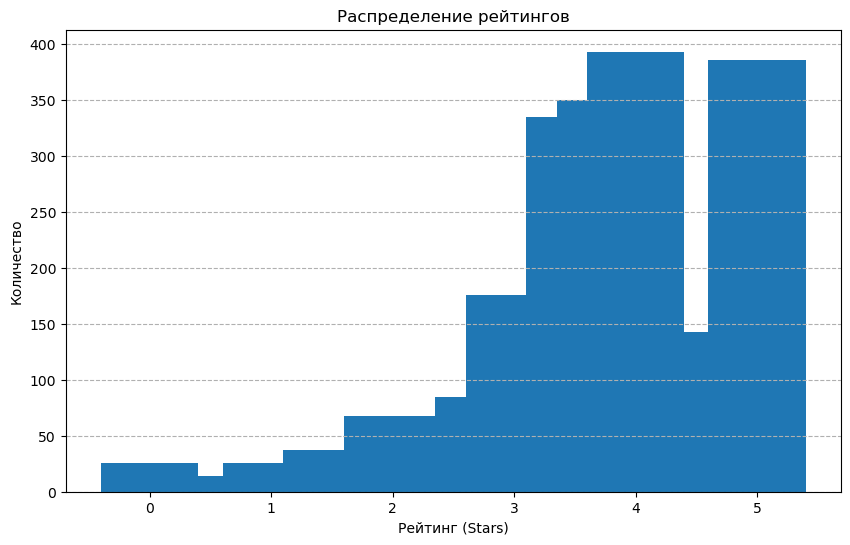

In [31]:
### распределение рейтингов

plt.figure(figsize=(10, 6))
plt.bar(df['Stars'].value_counts().index, df['Stars'].value_counts().values)
plt.title('Распределение рейтингов')
plt.xlabel('Рейтинг (Stars)')
plt.ylabel('Количество')
plt.grid(axis = 'y', linestyle = '--')
plt.show()

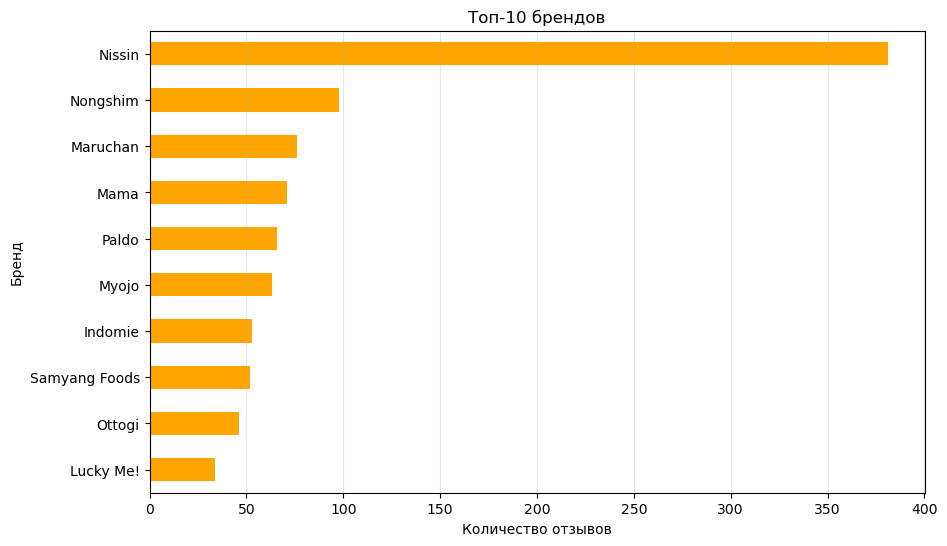

In [40]:
### найдем топ 10 брендов по количеству отзывов

top_brands = df["Brand"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_brands.sort_values().plot(kind="barh", color="orange")
plt.title("Топ-10 брендов")
plt.xlabel("Количество отзывов")
plt.ylabel("Бренд")
plt.grid(axis="x", alpha=0.3)
plt.show()

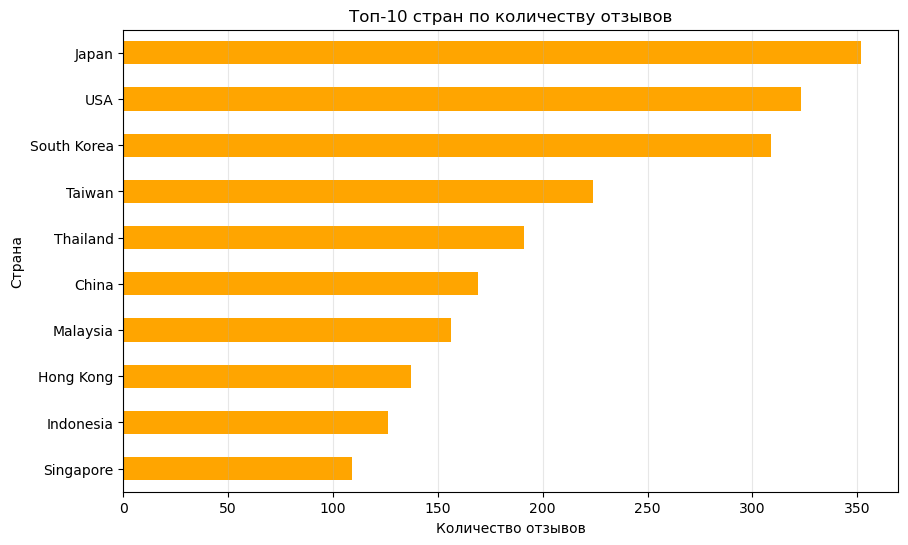

In [43]:
### найдем топ стран по количеству отзывов

top_countries = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_countries.sort_values().plot(kind="barh", color="orange")
plt.title("Топ-10 стран по количеству отзывов")
plt.xlabel("Количество отзывов")
plt.ylabel("Страна")
plt.grid(axis="x", alpha=0.3)
plt.show()

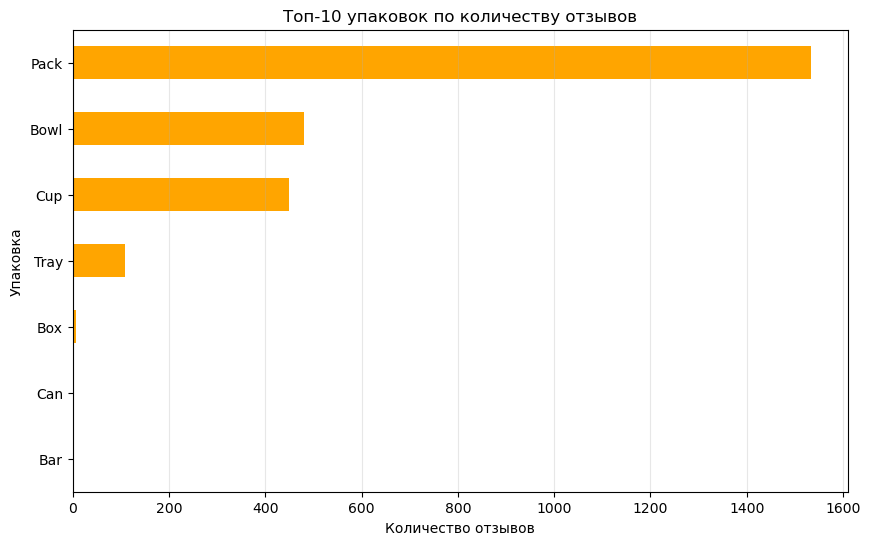

In [44]:
### проверим топ упаковок по количеству отзывов

style_counts = df["Style"].value_counts().head(10)
plt.figure(figsize=(10, 6))
style_counts.sort_values().plot(kind="barh", color="orange")
plt.title("Топ-10 упаковок по количеству отзывов")
plt.xlabel("Количество отзывов")
plt.ylabel("Упаковка")
plt.grid(axis="x", alpha=0.3)
plt.show()

### Статистики по рейтингу

In [47]:
### топ-10 брендов по среднему рейтингу

brand_rating = (
    df.groupby("Brand")["Stars"]
    .agg(["mean", "count"])
    .query("count >= 10")  # фильтруем бренды с количеством отзывов >= 10
    .sort_values(by="mean", ascending=False)
)
brand_rating_top10 = brand_rating.head(10)

print(brand_rating_top10)

                    mean  count
Brand                          
MyKuali         4.947917     24
Yamachan        4.568182     11
Vit's           4.211538     13
KOKA            4.210000     25
ABC             4.208333     12
Sakurai Foods   4.175000     10
Takamori Kosan  4.160714     14
Mi Sedaap       4.145833     12
Deshome         4.134615     13
Wugudaochang    4.125000     10


In [48]:
### топ 10 стран по среднему рейтингу

country_rating = (
    df.groupby("Country")["Stars"]
    .agg(["mean", "count"])
    .query("count >= 10")  # фильтруем страны с количеством отзывов >= 10
    .sort_values(by="mean", ascending=False)
)
country_rating_top10 = country_rating.head(10)
print(country_rating_top10)

                 mean  count
Country                     
Malaysia     4.154194    155
Singapore    4.126147    109
Indonesia    4.067460    126
Japan        3.981605    352
Myanmar      3.946429     14
Hong Kong    3.801825    137
South Korea  3.790554    307
Mexico       3.730000     25
Taiwan       3.665402    224
Germany      3.638889     27


In [57]:
### топ 10 названий блюд по среднему рейтингу

variety_rating = (
    df.groupby("Variety")
    .agg(
        Средний_рейтинг=("Stars", "mean"),
        Количество_отзывов=("Stars", "size")
        )
    .query("Количество_отзывов >= 3")
    .sort_values("Средний_рейтинг", ascending=False)
)

variety_rating_top10 = variety_rating.head(10)
print(variety_rating_top10)

                                     Средний_рейтинг  Количество_отзывов
Variety                                                                 
Kokomen Spicy Chicken                       4.750000                   3
Yakisoba                                    4.583333                   6
Curry Udon                                  4.562500                   4
Soy Sauce                                   3.916667                   3
Curry Flavour Instant Noodles               3.875000                   4
Kung Fu Artificial Beef Rice Noodle         3.750000                   3
Artificial Spicy Beef                       3.687500                   4
Beef                                        3.535714                   7
Imitation Chicken Vegetarian                3.500000                   3
Kimchi                                      3.466667                   3


In [ ]:
### посмотрим на слова в названиях блюд и их частоту

words = (
    df["Variety"]
    .dropna()
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", "", regex=True)
    .str.split()
    .explode()
)

words = words[words.str.len() > 2]
word_counts = words.value_counts()

display(word_counts.head(20))

Variety
noodles       675
noodle        519
instant       447
flavour       406
ramen         342
chicken       329
flavor        323
spicy         276
beef          233
cup           197
soup          196
with          170
sauce         145
rice          143
artificial    133
tom           128
curry         127
shrimp        127
hot           119
seafood       109
Name: count, dtype: int64

In [71]:
### рассмотрим колонку Top Ten

df["Top Ten"] = df["Top Ten"].replace(r"^\s*$", pd.NA, regex=True)

top_ten = df[df["Top Ten"].notna()].copy()

print("Количество записей в Top Ten:", len(top_ten))
print("Средний рейтинг в Top Ten:", top_ten["Stars"].mean())
print("Средний рейтинг всего датасета:", df["Stars"].dropna().mean())

display(
    top_ten[["Brand", "Variety", "Country", "Stars", "Top Ten"]]
    .sort_values("Stars", ascending=False)
    .head(20)
)

Количество записей в Top Ten: 37
Средний рейтинг в Top Ten: 4.918918918918919
Средний рейтинг всего датасета: 3.6546759798214974


,Brand,Variety,Country,Stars,Top Ten
616,MAMA,Instant Noodles Coconut Milk Flavour,Myanmar,5.0,2016 #10
633,Prima Taste,Singapore Laksa Wholegrain La Mian,Singapore,5.0,2016 #1
655,Prima,Juzz's Mee Creamy Chicken Flavour,Singapore,5.0,2016 #8
673,Prima Taste,Singapore Curry Wholegrain La Mian,Singapore,5.0,2016 #5
752,Tseng Noodles,Scallion With Sichuan Pepper Flavor,Taiwan,5.0,2016 #9
891,Wugudaochang,Tomato Beef Brisket Flavor Purple Potato Noodle,China,5.0,2016 #7
942,A-Sha Dry Noodle,Veggie Noodle Tomato Noodle With Vine Ripened ...,Taiwan,5.0,2015 #10
963,MyKuali,Penang Hokkien Prawn Noodle (New Improved Taste),Malaysia,5.0,2015 #7
995,CarJEN,Nyonya Curry Laksa,Malaysia,5.0,2015 #4
1059,Maruchan,Gotsumori Sauce Yakisoba,Japan,5.0,2015 #9


In [66]:
print("Бренды в Top Ten:")
print(top_ten["Brand"].value_counts().head(10))

print("\nСтраны в Top Ten:")
print(top_ten["Country"].value_counts().head(10))

Бренды в Top Ten:
Brand
Prima Taste        5
Indomie            3
Nongshim           3
Mama               3
MyKuali            3
Sapporo Ichiban    2
Myojo              2
Paldo              2
Mamee              2
Wugudaochang       1
Name: count, dtype: int64

Страны в Top Ten:
Country
Singapore      7
Japan          6
Malaysia       6
South Korea    5
Indonesia      4
Thailand       3
Taiwan         2
Myanmar        1
China          1
USA            1
Name: count, dtype: int64


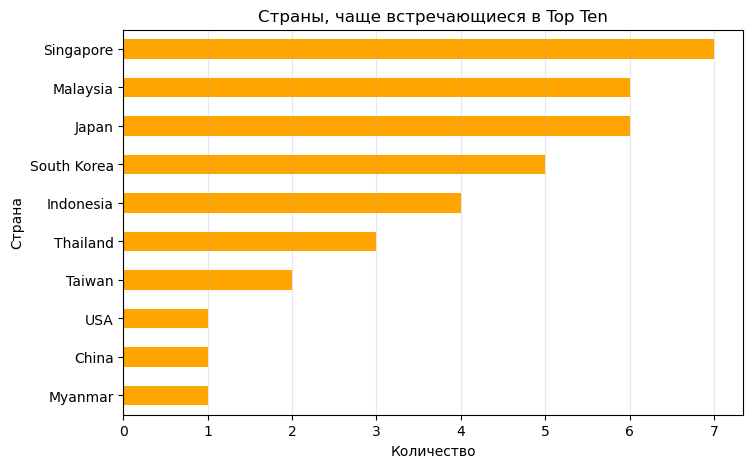

In [69]:
top_ten_country = top_ten["Country"].value_counts().head(10)

plt.figure(figsize=(8, 5))
top_ten_country.sort_values().plot(kind="barh", color="orange")
plt.title("Страны, чаще встречающиеся в Top Ten")
plt.xlabel("Количество")
plt.ylabel("Страна")
plt.grid(axis="x", alpha=0.3)
plt.show()

## Итоговые выводы

После анализа датасета видно, что большинство раменов оценивается в среднем и выше среднего диапазоне. Средняя оценка по всем заполненным значениям примерно 3.65, а медиана - 3.75. Это говорит о том, что в целом ассортимент достаточно сбалансирован, но при этом есть и заметное количество продуктов с низкими и очень высокими оценками.

Самым популярным брендом по количеству отзывов оказался Nissin. Бренд может встречаться чаще просто потому, что его больше покупают или больше о нём пишут отзывы. Поэтому для более корректного сравнения важно смотреть и на число отзывов, и на средний рейтинг.

Если смотреть на бренды с достаточным количеством оценок, то самые сильные показатели показывают MyKuali, KOKA, Indomie, Samyang Foods и некоторые другие бренды. То есть высокий рейтинг встречается не только у самых массовых брендов, но и у тех, кто стабильно держит хороший уровень качества.

Самой распространённой упаковкой оказался Pack.

По странам особенно выделяются Malaysia, Singapore и Indonesi, у этих стран средний рейтинг заметно выше, чем у многих других регионов. Это может говорить о том, что в этих странах сильнее развита рецептура и более высокая общая оценка рамена. Japan тоже имеет много отзывов, но по среднему рейтингу отстаёт от лидеров.

Важную роль играет и колонка Top Ten. В этой выборке средний рейтинг резко выше, чем в среднем по всему датасету, что подтверждает, что “лучшие” продукты действительно выделяются по качеству. В Top Ten чаще встречаются продукты из Singapore, Malaysia, Japan и South Korea, а также сильные бренды вроде Prima Taste, MyKuali, Mama и Nongshim.

Также важно отметить, что значения **Unrated** не участвуют в расчётах среднего рейтинга, потому что это не числовые оценки.

Главный вывод в том, что “идеальный рамен”  это продукт с высоким средним рейтингом, достаточным количеством оценок и стабильной репутацией.

Если смотреть на весь набор данных в целом, то хороший рамен чаще всего связан с сильными брендами, странами с развитой ramen-культурой и продуктами, которые стабильно получают высокие оценки, а не только с большой популярностью.